# 05 · Les résultats

La note finale a été faite **une seule fois**, le 24/09/2026, sur **test100** (100 tickets jamais vus), avec le
bot figé au tag `v7-final`. On compare la version finale v7 au point de départ v0, sur les mêmes tickets.

Ce notebook montre :
1. v0 contre v7, champ par champ, avec intervalles de confiance à 95 % et test de McNemar ;
2. les matrices de confusion de la v7 ;
3. une carte de chaleur produit × gravité ;
4. la comparaison val60, holdout20 et test100.

On lit seulement les fichiers de résultats du run final (listés dans `eval/reports/final_test100.md`).
Rien n'est relancé, aucun modèle n'est appelé, le fichier test100 n'est pas ouvert.

In [1]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from outils import (RESULTS, RUNS, read_run, load, compare, bootstrap_ci, FIELDS, ALL, figure, finish, sobre,
                    kpi, pct, FOND, TEXTE, GRIS, GRIS_FONCE, BLEU, ROUGE)

In [2]:
meta7, rows7, sum7 = read_run("test100_v7")
meta0, rows0, sum0 = read_run("test100_v0")
print("v7 :", meta7["prompt_file"], "· garde :", meta7["guard"], "· commit", meta7["git"]["commit"][:7],
      "· arbre propre :", not meta7["git"]["dirty"])
print("v0 :", meta0["prompt_file"], "· garde :", meta0["guard"], "· commit", meta0["git"]["commit"][:7])
print("Tickets :", len(rows7), len(rows0), "· modèle", meta7["model"], "· température", meta7["options"]["temperature"])

v7 : prompts/v7_sous_motif.txt · garde : True · commit 4c52a69 · arbre propre : True
v0 : prompts/v0_baseline.txt · garde : False · commit 4c52a69
Tickets : 100 100 · modèle llama3.1:8b · température 0.0


## 1. v0 contre v7, champ par champ

- **Précision** : part des 100 tickets où le champ est juste.
- **IC 95 %** : intervalle de confiance par bootstrap (2 000 tirages), calculé par le harnais.
- **McNemar** : test apparié sur les mêmes tickets. On compte les tickets corrigés (faux en v0, justes en v7)
  et cassés (l'inverse). p < 0,05 : la différence n'est pas due au hasard.

In [3]:
_, t0, _ = load(RESULTS / RUNS["test100_v0"])
_, t7, _ = load(RESULTS / RUNS["test100_v7"])
cmp = compare(t0, t7)

def ic(summary, rows, champ):
    if champ == ALL:
        hits = [int(all(r["hits"][f] for f in FIELDS)) for r in rows]
        return sum(hits) / len(hits), bootstrap_ci(hits, 2000, random.Random(42))
    a = summary["accuracy"][champ]
    return a["value"], tuple(a["ci95"])

table = []
for champ in FIELDS + [ALL]:
    (a0, i0), (a7, i7) = ic(sum0, rows0, champ), ic(sum7, rows7, champ)
    c = cmp[champ]
    table.append({"champ": champ, "v0": a0, "v0 IC": i0, "v7": a7, "v7 IC": i7,
                  "corrigés": len(c["fixed"]), "cassés": len(c["broken"]), "p": c["p_value"]})
res = pd.DataFrame(table).set_index("champ")
affiche = res.copy()
for v in ("v0", "v7"):
    affiche[v] = [f"{pct(a)} [{pct(lo, 0)} ; {pct(hi, 0)}]" for a, (lo, hi) in zip(res[v], res[f"{v} IC"])]
affiche["p"] = res["p"].map(lambda p: "< 0,001" if p < 0.001 else f"{p:.3f}".replace(".", ","))
affiche.drop(columns=["v0 IC", "v7 IC"])

,v0,v7,corrigés,cassés,p
champ,,,,,
label,"38,0 % [28 % ; 48 %]","88,0 % [81 % ; 94 %]",50,0,"< 0,001"
product,"54,0 % [44 % ; 63 %]","84,0 % [76 % ; 91 %]",36,6,"< 0,001"
severity,"58,0 % [48 % ; 68 %]","83,0 % [75 % ; 90 %]",26,1,"< 0,001"
is_complaint,"82,0 % [74 % ; 89 %]","84,0 % [76 % ; 91 %]",9,7,"0,804"
unauthorized_payment,"94,0 % [89 % ; 98 %]","96,0 % [92 % ; 99 %]",4,2,"0,688"
tous les champs,"8,0 % [3 % ; 14 %]","62,0 % [52 % ; 71 %]",55,1,"< 0,001"


In [4]:
print(f"sous_motif (v7 seulement) : {pct(sum7['accuracy']['sous_motif']['value'])}")

sous_motif (v7 seulement) : 66,0 %


In [5]:
tj = res.loc[ALL]
kpi("test100_tout_juste_v0_v7", {"v0": round(100 * tj.v0), "v7": round(100 * tj.v7),
                                 "ic95_v7": [round(100 * x) for x in tj["v7 IC"]], "mcnemar_p": "< 0,001",
                                 "corriges": int(tj["corrigés"]), "casses": int(tj["cassés"])},
    "tickets entièrement justes sur test100 (%), v0 puis v7", "eval/results/20260924T125426Z (v0) et 20260924T121931Z (v7)",
    "07_test100_v0_v7.png")
kpi("test100_label_v0_v7", {"v0": round(100 * res.loc["label", "v0"]), "v7": round(100 * res.loc["label", "v7"]),
                            "corriges": int(res.loc["label", "corrigés"]), "casses": int(res.loc["label", "cassés"])},
    "précision du label sur test100 (%), v0 puis v7", "eval/results/20260924T121931Z et 20260924T125426Z",
    "07_test100_v0_v7.png")
kpi("test100_is_complaint_v0_v7", {"v0": round(100 * res.loc["is_complaint", "v0"]),
                                   "v7": round(100 * res.loc["is_complaint", "v7"]),
                                   "mcnemar_p": round(res.loc["is_complaint", "p"], 3)},
    "réclamations détectées : pas de gain significatif (limite)", "eval/results/20260924T121931Z et 20260924T125426Z",
    "07_test100_v0_v7.png")
kpi("test100_sous_motif_v7", round(100 * sum7["accuracy"]["sous_motif"]["value"]),
    "précision du sous-motif (16 valeurs) sur test100, v7, en %", "eval/results/20260924T121931Z")

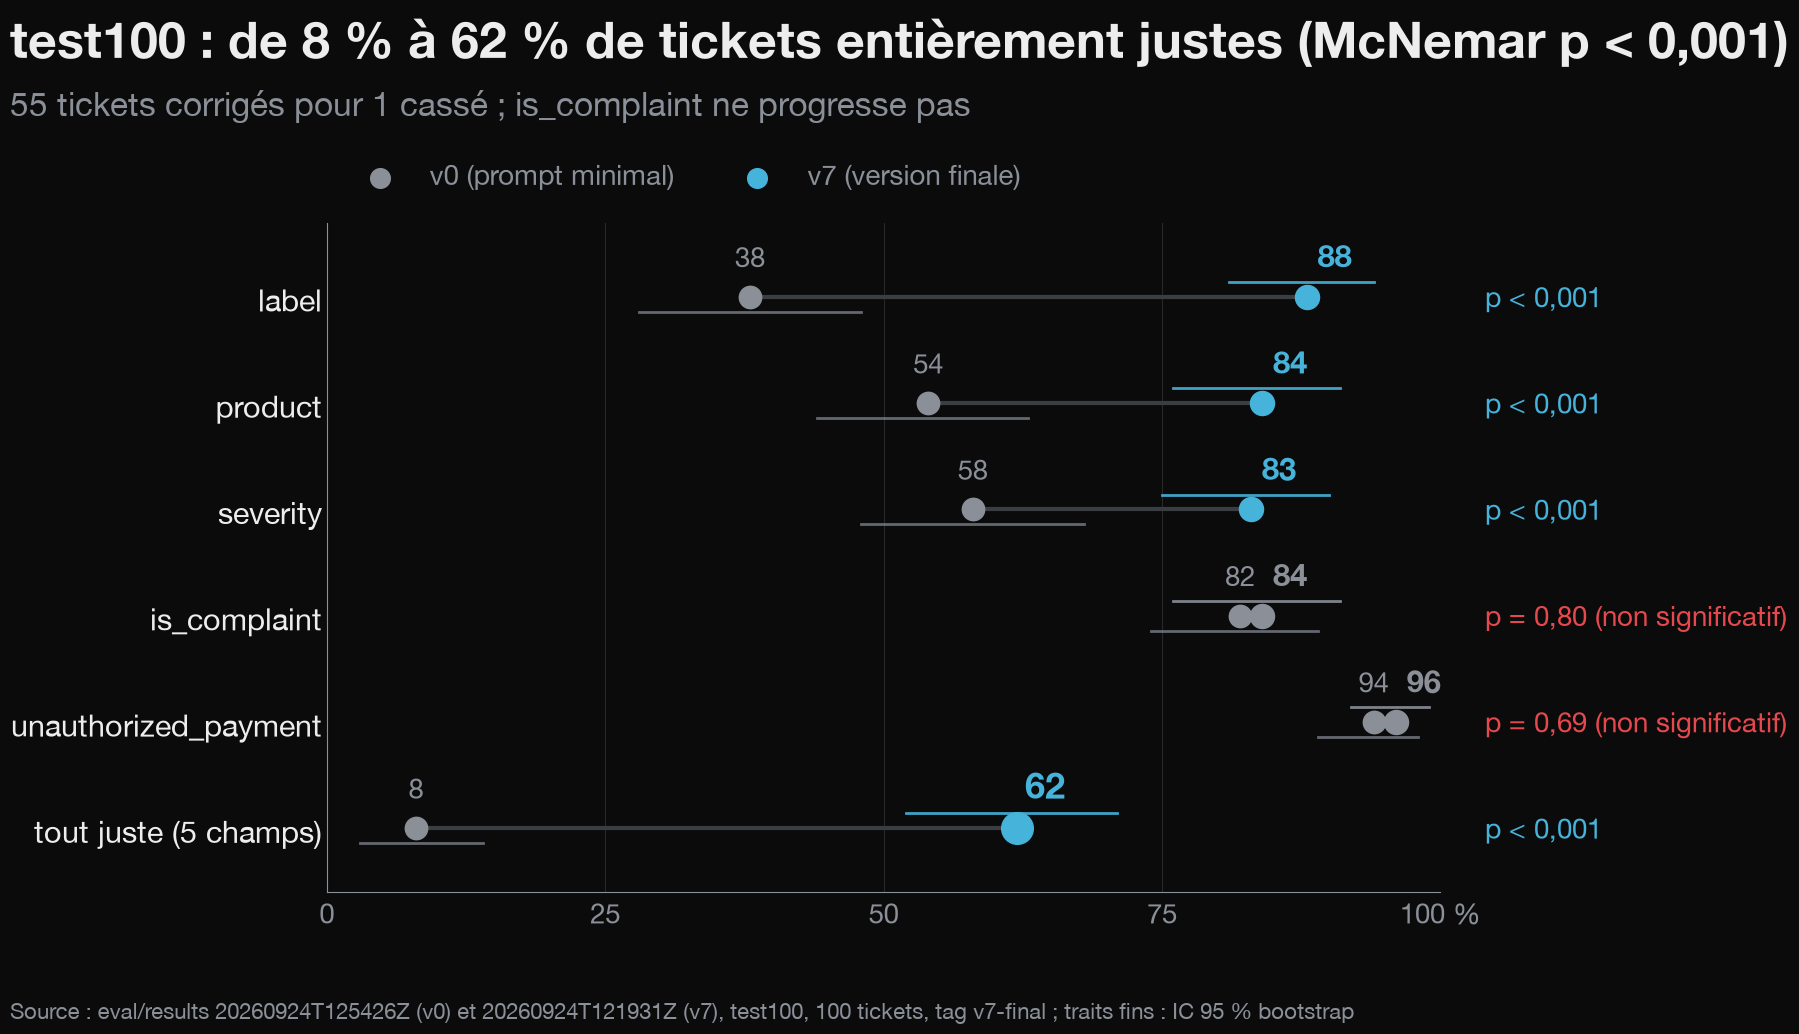

In [6]:
NOMS = {**{f: f for f in FIELDS}, ALL: "tout juste (5 champs)"}
fig, ax = figure(left=0.2, right=0.78, top=0.76)
ordre = list(res.index)[::-1]
for y, champ in enumerate(ordre):
    r = res.loc[champ]
    signif = r.p < 0.05
    fort = champ == ALL
    ax.plot([r.v0 * 100, r.v7 * 100], [y, y], color=GRIS_FONCE, linewidth=3, zorder=1)
    ax.plot([x * 100 for x in r["v0 IC"]], [y - 0.14] * 2, color=GRIS, linewidth=2, alpha=0.7)
    ax.plot([x * 100 for x in r["v7 IC"]], [y + 0.14] * 2, color=BLEU if signif else GRIS, linewidth=2, alpha=0.9)
    ax.scatter(r.v0 * 100, y, s=260, color=GRIS, zorder=3)
    ax.scatter(r.v7 * 100, y, s=520 if fort else 300, color=BLEU if signif else GRIS, zorder=3)
    ax.text(r.v7 * 100 + (2.5 if r.v7 >= r.v0 else -2.5), y + 0.28, f"{r.v7 * 100:.0f}", ha="center",
            fontsize=26 if fort else 22, weight="bold", color=BLEU if signif else GRIS)
    ax.text(r.v0 * 100, y + 0.28, f"{r.v0 * 100:.0f}", ha="center", fontsize=20, color=GRIS)
    txt = "p < 0,001" if r.p < 0.001 else f"p = {r.p:.2f}".replace(".", ",") + " (non significatif)"
    ax.text(104, y, txt, va="center", fontsize=20, color=BLEU if signif else ROUGE)
ax.set_yticks(range(len(ordre)), [NOMS[c] for c in ordre])
ax.tick_params(axis="y", labelsize=22, labelcolor=TEXTE)
ax.set_xlim(0, 100)
ax.set_ylim(-0.6, len(ordre) - 0.3)
ax.set_xticks([0, 25, 50, 75, 100], ["0", "25", "50", "75", "100 %"])
sobre(ax)
ax.xaxis.grid(True, color="#26282C")
ax.set_axisbelow(True)
ax.scatter([], [], s=200, color=GRIS, label="v0 (prompt minimal)")
ax.scatter([], [], s=200, color=BLEU, label="v7 (version finale)")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.01), ncol=2, fontsize=20, labelcolor=GRIS)
finish(fig, 7, "test100_v0_v7",
       f"test100 : de {tj.v0 * 100:.0f} % à {tj.v7 * 100:.0f} % de tickets entièrement justes (McNemar p < 0,001)",
       "eval/results 20260924T125426Z (v0) et 20260924T121931Z (v7), test100, 100 tickets, tag v7-final ; "
       "traits fins : IC 95 % bootstrap",
       f"{int(tj['corrigés'])} tickets corrigés pour {int(tj['cassés'])} cassé ; is_complaint ne progresse pas")
plt.show()

**À retenir.** La v7 progresse nettement sur label, product, severity et les tickets entièrement justes.
Elle ne progresse pas de façon significative sur les réclamations (`is_complaint`) ni sur les paiements non
autorisés, où v0 était déjà haut.

## 2. Matrices de confusion de la v7

Lignes : la bonne réponse. Colonnes : ce que le bot a répondu. La diagonale = les réponses justes.

In [7]:
ORDRES = {"label": ["billing", "bug", "other"],
          "product": ["card", "transfer", "direct_debit", "account", "unknown"],
          "severity": ["low", "medium", "high"]}
matrices = {}
for champ, vals in ORDRES.items():
    m = pd.DataFrame(sum7["confusion"][champ]).T.reindex(index=vals, columns=vals).fillna(0).astype(int)
    m.index.name, m.columns.name = "vérité", "prédit"
    matrices[champ] = m
    print(f"\n{champ}  ({np.trace(m.values)} justes sur {m.values.sum()})")
    print(m)


label  (88 justes sur 100)
prédit   billing  bug  other
vérité                      
billing       27    1      6
bug            1   28      4
other          0    0     33

product  (84 justes sur 100)
prédit        card  transfer  direct_debit  account  unknown
vérité                                                      
card            24         0             0        1        1
transfer         0        16             0        1        4
direct_debit     1         0            12        1        0
account          3         0             0       26        1
unknown          1         0             0        2        6

severity  (83 justes sur 100)
prédit  low  medium  high
vérité                   
low      32       0     0
medium   12      21     3
high      0       2    30


In [8]:
erreurs = [(champ, t, p, m.loc[t, p]) for champ, m in matrices.items() for t in m.index for p in m.columns if t != p]
champ_e, vrai_e, pred_e, n_e = max(erreurs, key=lambda e: e[3])
n_vrai = matrices[champ_e].loc[vrai_e].sum()
print(f"Erreur la plus fréquente : {champ_e} {vrai_e} lu comme {pred_e}, {n_e} tickets sur {n_vrai}")
kpi("test100_erreur_principale_v7", {"champ": champ_e, "vrai": vrai_e, "predit": pred_e, "n": int(n_e), "sur": int(n_vrai)},
    "erreur la plus fréquente de la v7 sur test100", "eval/results/20260924T121931Z (matrices de confusion)",
    "08_confusion_v7.png")

Erreur la plus fréquente : severity medium lu comme low, 12 tickets sur 36


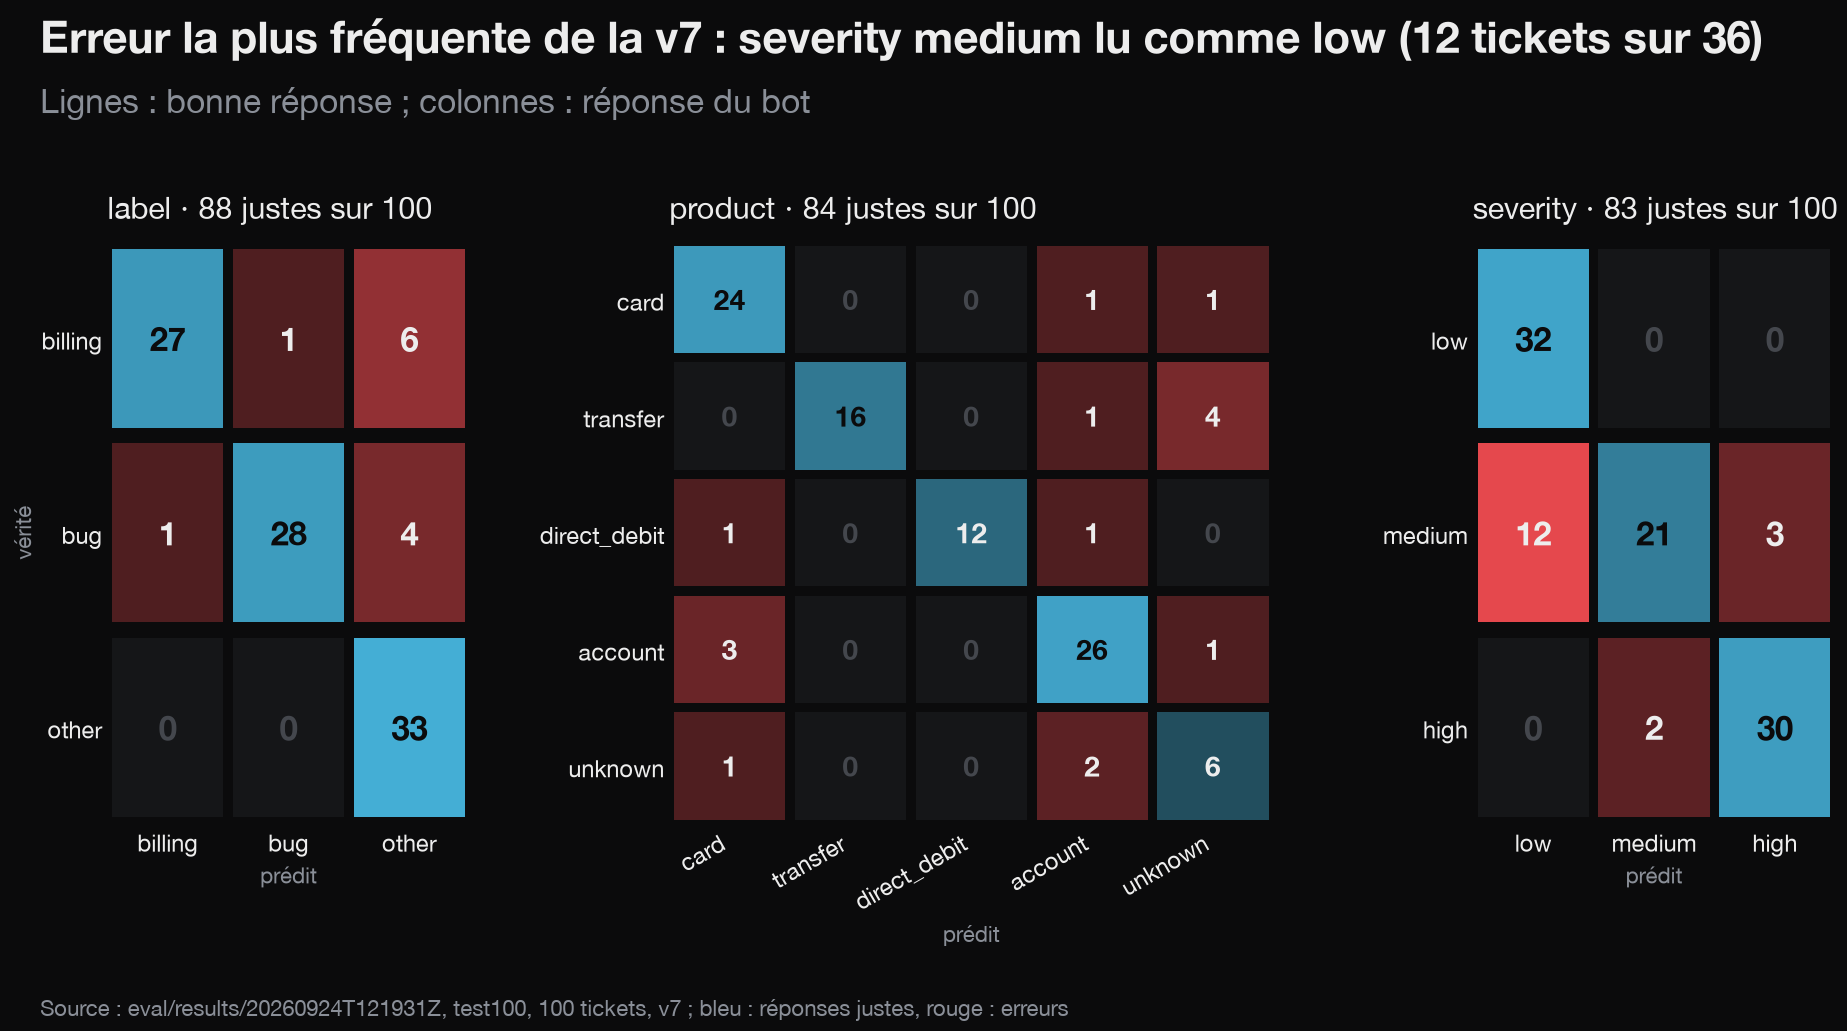

In [9]:
fig, axes = figure(1, 3, top=0.74, left=0.07, bottom=0.2, gridspec_kw={"width_ratios": [3, 5, 3]})
fig.subplots_adjust(wspace=0.45)
for ax, (champ, m) in zip(axes, matrices.items()):
    n = len(m)
    ax.set_xlim(-0.5, n - 0.5)
    ax.set_ylim(n - 0.5, -0.5)
    ligne_max = m.sum(axis=1).max()
    for i, t in enumerate(m.index):
        for j, p in enumerate(m.columns):
            v = m.loc[t, p]
            if i == j:
                fond, alpha, coul = BLEU, 0.25 + 0.75 * v / ligne_max, FOND if v / ligne_max > 0.45 else TEXTE
            elif v:
                fond, alpha, coul = ROUGE, 0.25 + 0.75 * min(1, v / 12), TEXTE
            else:
                fond, alpha, coul = "#151618", 1, "#44474D"
            ax.add_patch(plt.Rectangle((j - 0.46, i - 0.46), 0.92, 0.92, color=fond, alpha=alpha, linewidth=0))
            ax.text(j, i, str(v), ha="center", va="center", fontsize=24 if n == 3 else 20, color=coul, weight="bold")
    ax.set_xticks(range(n), m.columns, rotation=0 if n == 3 else 30, ha="center" if n == 3 else "right", fontsize=17)
    ax.set_yticks(range(n), m.index, fontsize=17)
    ax.tick_params(length=0, labelcolor=TEXTE)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title(f"{champ} · {np.trace(m.values)} justes sur 100", fontsize=22)
    ax.set_xlabel("prédit", fontsize=16)
axes[0].set_ylabel("vérité", fontsize=16)
finish(fig, 8, "confusion_v7",
       f"Erreur la plus fréquente de la v7 : {champ_e} {vrai_e} lu comme {pred_e} ({n_e} tickets sur {n_vrai})",
       "eval/results/20260924T121931Z, test100, 100 tickets, v7 ; bleu : réponses justes, rouge : erreurs",
       "Lignes : bonne réponse ; colonnes : réponse du bot")
plt.show()

**À retenir.** Quand la v7 se trompe de catégorie, elle choisit presque toujours `other`. Sur la gravité, elle
sous-estime : un tiers des tickets `medium` sont classés `low`, jamais l'inverse.

## 3. Carte de chaleur produit × gravité

Pour chaque case, la part des tickets **entièrement justes** (5 champs) en v7, et le nombre de tickets.

In [10]:
df = pd.DataFrame([{"product": r["gold"]["product"], "severity": r["gold"]["severity"],
                    "ok": all(r["hits"][f] for f in FIELDS)} for r in rows7])
prods, sevs = ORDRES["product"], ORDRES["severity"]
taux = pd.crosstab(df["product"], df["severity"], values=df.ok, aggfunc="mean").reindex(index=prods, columns=sevs)
nb = pd.crosstab(df["product"], df["severity"]).reindex(index=prods, columns=sevs).fillna(0).astype(int)
ok = pd.crosstab(df["product"], df["severity"], values=df.ok, aggfunc="sum").reindex(index=prods, columns=sevs).fillna(0).astype(int)
(taux * 100).round(0)

severity,low,medium,high
product,,,
card,67.0,40.0,69.0
transfer,50.0,43.0,100.0
direct_debit,100.0,57.0,40.0
account,80.0,57.0,75.0
unknown,100.0,0.0,NaN


In [11]:
par_sev = df.groupby("severity").ok.agg(["sum", "count"]).reindex(sevs)
par_sev["taux"] = par_sev["sum"] / par_sev["count"]
par_sev

,sum,count,taux
severity,,,
low,24,32,0.750000
medium,15,36,0.416667
high,23,32,0.718750


In [12]:
autres = df[df.severity != "medium"].ok.mean()
kpi("test100_medium_tout_juste_v7", {"medium_pct": round(100 * par_sev.loc["medium", "taux"]),
                                     "low_high_pct": round(100 * autres),
                                     "medium_n": int(par_sev.loc["medium", "count"])},
    "tickets entièrement justes en v7 selon la gravité : medium contre low et high", "eval/results/20260924T121931Z",
    "09_produit_gravite.png")

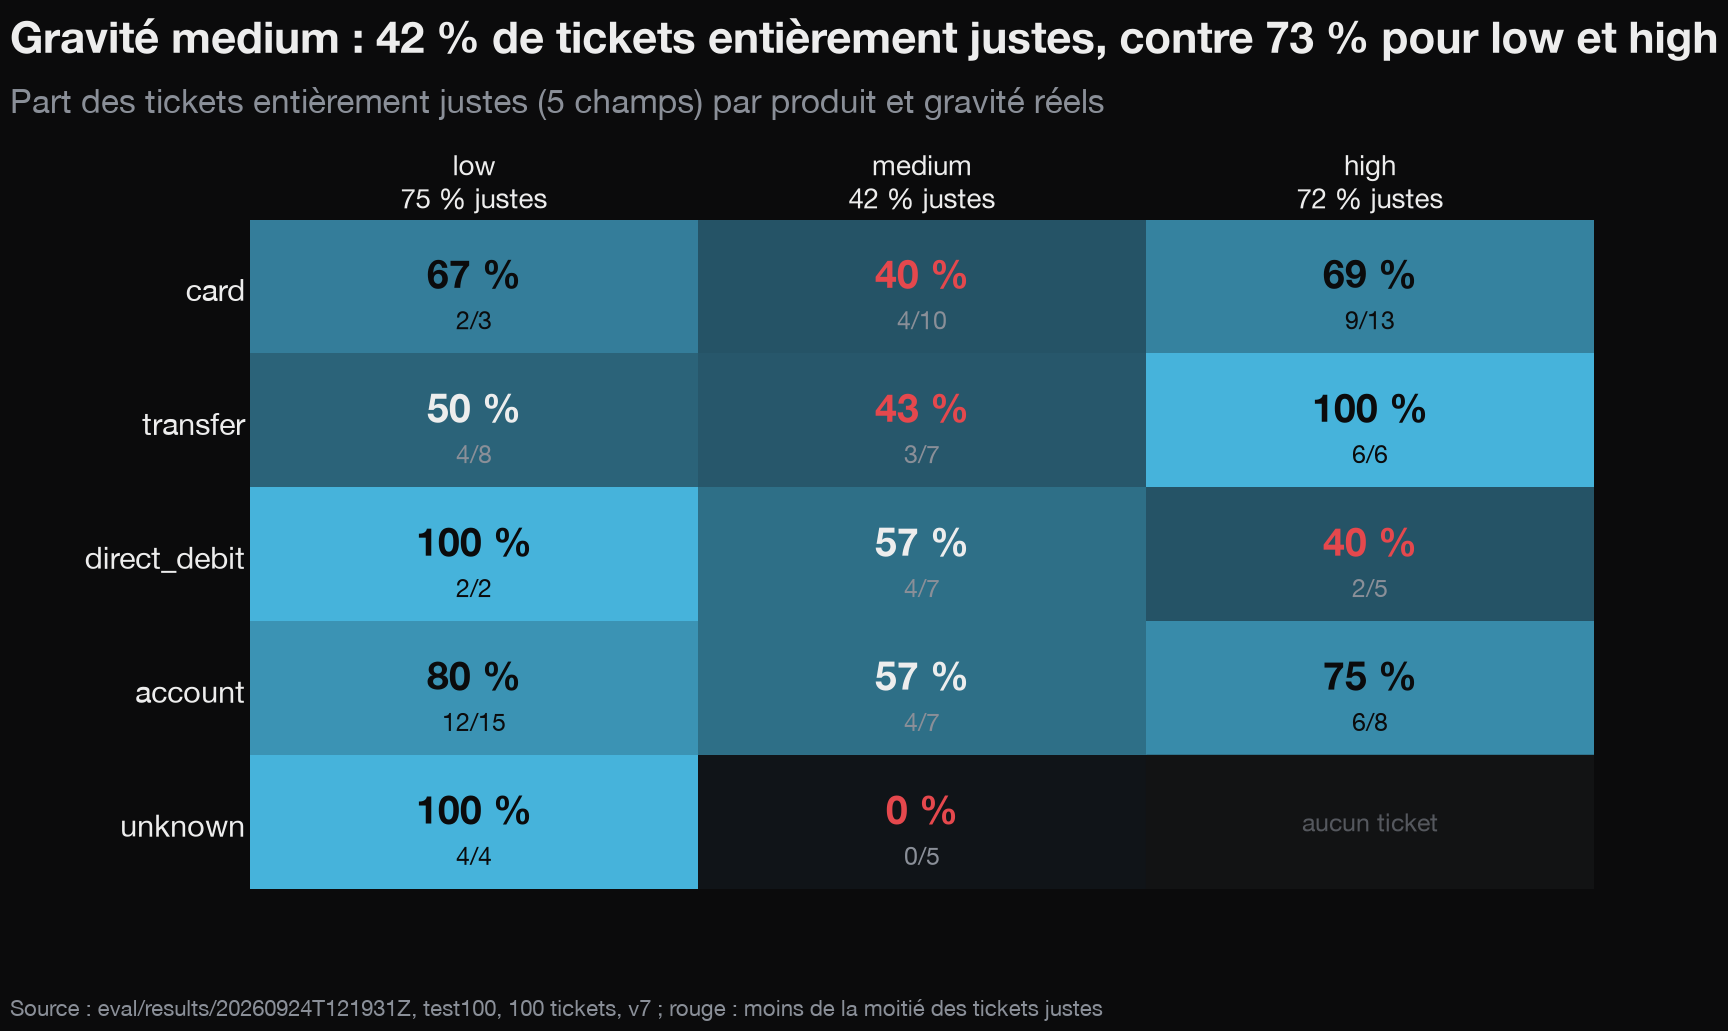

In [13]:
cmap = LinearSegmentedColormap.from_list("bleu", ["#101418", BLEU])
fig, ax = figure(left=0.16, right=0.86, top=0.76)
ax.imshow(taux.values.astype(float), cmap=cmap, vmin=0, vmax=1, aspect="auto")
for i, p in enumerate(prods):
    for j, s in enumerate(sevs):
        if nb.loc[p, s] == 0:
            ax.text(j, i, "aucun ticket", ha="center", va="center", fontsize=18, color="#55585E")
            ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, color="#121314"))
            continue
        t = taux.loc[p, s]
        ax.text(j, i - 0.1, f"{t * 100:.0f} %", ha="center", va="center", fontsize=28, weight="bold",
                color=ROUGE if t < 0.5 else (FOND if t > 0.6 else TEXTE))
        ax.text(j, i + 0.25, f"{ok.loc[p, s]}/{nb.loc[p, s]}", ha="center", va="center", fontsize=18,
                color=FOND if t > 0.6 else GRIS)
ax.set_xticks(range(3), [f"{s}\n{par_sev.loc[s, 'taux'] * 100:.0f} % justes" for s in sevs], fontsize=20)
ax.set_yticks(range(len(prods)), prods, fontsize=22)
ax.xaxis.tick_top()
ax.tick_params(length=0, labelcolor=TEXTE)
for sp in ax.spines.values():
    sp.set_visible(False)
finish(fig, 9, "produit_gravite",
       f"Gravité medium : {par_sev.loc['medium', 'taux'] * 100:.0f} % de tickets entièrement justes, "
       f"contre {autres * 100:.0f} % pour low et high",
       "eval/results/20260924T121931Z, test100, 100 tickets, v7 ; rouge : moins de la moitié des tickets justes",
       "Part des tickets entièrement justes (5 champs) par produit et gravité réels")
plt.show()

**À retenir.** La difficulté est dans la gravité intermédiaire : les tickets `medium` sont les moins bien traités,
quel que soit le produit. Les cases sont petites (2 à 15 tickets) : ce sont des tendances, pas des mesures précises.

## 4. val60, holdout20 et test100

Les mêmes versions v0 et v7 sur trois jeux :
- **val60** a servi à choisir les versions ;
- **test100** n'avait jamais été vu (même auteur des tickets que val60) ;
- **holdout20** : 20 attaques écrites par un **autre modèle** (qwen2.5:7b), dans un autre style.

In [14]:
def tout_juste(run):
    _, rows, _ = read_run(run)
    return sum(all(r["hits"][f] for f in FIELDS) for r in rows) / len(rows), len(rows)

comp = []
for jeu in ["val60", "test100", "holdout20"]:
    for v in ["v0", "v7"]:
        _, rows, s = read_run(f"{jeu}_{v}")
        comp.append({"jeu": jeu, "version": v, "n": len(rows), "tout juste": tout_juste(f"{jeu}_{v}")[0],
                     **{f: s["accuracy"][f]["value"] for f in FIELDS}})
comp = pd.DataFrame(comp).set_index(["jeu", "version"])
(comp.drop(columns="n") * 100).round(1)

tout juste  label  product  severity  is_complaint  \
jeu       version                                                       
val60     v0             11.7   40.0     53.3      60.0          83.3   
          v7             61.7   91.7     90.0      83.3          85.0   
test100   v0              8.0   38.0     54.0      58.0          82.0   
          v7             62.0   88.0     84.0      83.0          84.0   
holdout20 v0             10.0   55.0     60.0      45.0          60.0   
          v7             20.0   55.0     40.0      55.0          70.0   

                   unauthorized_payment  
jeu       version                        
val60     v0                       96.7  
          v7                       98.3  
test100   v0                       94.0  
          v7                       96.0  
holdout20 v0                       85.0  
          v7                      100.0

In [15]:
v7 = comp.xs("v7", level="version")["tout juste"]
kpi("v7_tout_juste_par_jeu", {j: round(100 * v7[j], 1) for j in v7.index},
    "tickets entièrement justes en v7 : val60, test100, holdout20 (%)",
    "eval/results (runs v7 de val60, test100, holdout20 ; eval/reports/final_test100.md)", "10_trois_jeux.png")

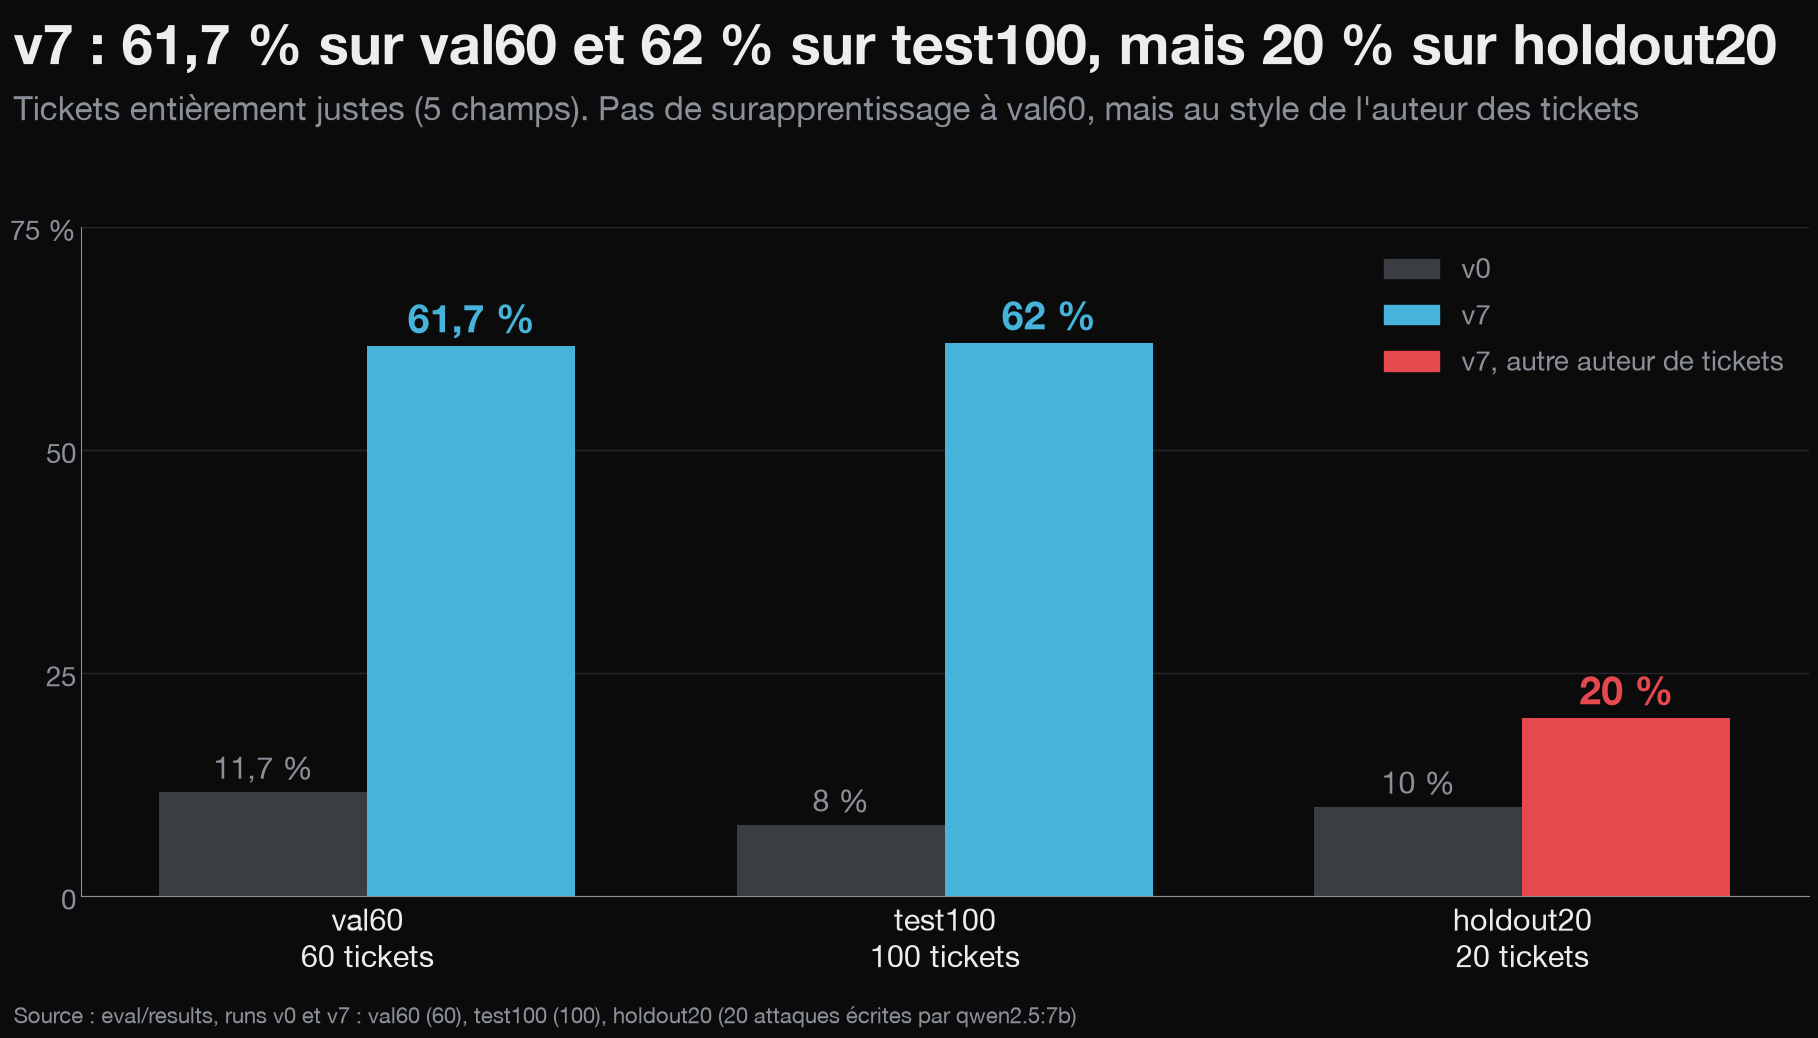

In [16]:
fig, ax = figure(top=0.76)
jeux = ["val60", "test100", "holdout20"]
largeur = 0.36
for i, jeu in enumerate(jeux):
    a0, a7 = comp.loc[(jeu, "v0"), "tout juste"], comp.loc[(jeu, "v7"), "tout juste"]
    c7 = ROUGE if jeu == "holdout20" else BLEU
    ax.bar(i - largeur / 2, a0 * 100, largeur, color=GRIS_FONCE)
    ax.bar(i + largeur / 2, a7 * 100, largeur, color=c7)
    ax.text(i - largeur / 2, a0 * 100 + 1.5, pct(a0).replace(",0 %", " %"), ha="center", fontsize=22, color=GRIS)
    ax.text(i + largeur / 2, a7 * 100 + 1.5, pct(a7).replace(",0 %", " %"), ha="center", fontsize=28, color=c7, weight="bold")
ax.set_xticks(range(3), [f"{j}\n{int(comp.loc[(j, 'v7'), 'n'])} tickets" for j in jeux], fontsize=22)
ax.tick_params(axis="x", labelcolor=TEXTE)
ax.set_ylim(0, 75)
ax.set_yticks([0, 25, 50, 75], ["0", "25", "50", "75 %"])
sobre(ax, grille_y=True)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=GRIS_FONCE, label="v0"), Patch(color=BLEU, label="v7"),
                   Patch(color=ROUGE, label="v7, autre auteur de tickets")],
          loc="upper right", fontsize=20, labelcolor=GRIS)
finish(fig, 10, "trois_jeux",
       f"v7 : {pct(v7['val60'])} sur val60 et {pct(v7['test100'], 0)} sur test100, mais {pct(v7['holdout20'], 0)} "
       "sur holdout20",
       "eval/results, runs v0 et v7 : val60 (60), test100 (100), holdout20 (20 attaques écrites par qwen2.5:7b)",
       "Tickets entièrement justes (5 champs). Pas de surapprentissage à val60, mais au style de l'auteur des tickets")
plt.show()

**À retenir.**
- val60 et test100 donnent presque le même score : choisir les versions sur val60 n'a pas gonflé les chiffres.
- Sur holdout20, écrit par un autre modèle, le score chute à 20 %. Le prompt a été réglé sur des tickets d'un
  seul style ; il se transpose mal à un autre auteur. holdout20 est petit (20) et ne contient que des attaques :
  c'est un signal, pas une mesure précise.